In [3]:
from pathlib import Path


# Caminho base dos arquivos
base_path = Path("./")  # ajuste se necessário

In [4]:
import json
import numpy as np
import pandas as pd


def compute_metrics_stats(json_path: str):
    """
    Computes the mean and standard deviation of training and testing metrics
    across multiple experiments stored in a JSON file.

    Args:
        json_path (str): Path to the JSON file.

    Returns:
        dict: Dictionary containing mean and std for each metric (train/test).
    """
    # Load data
    with open(json_path, "r") as f:
        data = json.load(f)

    # Ensure it's a list of experiments
    if not isinstance(data, list):
        data = [data]

    # Collect metrics
    train_metrics = {}
    test_metrics = {}

    for exp in data[0]["results"]:
        train = exp.get("train", {})
        test = exp.get("test", {})

        for k, v in train.items():
            train_metrics.setdefault(k, []).append(v)

        for k, v in test.items():
            test_metrics.setdefault(k, []).append(v)

    # Compute mean and std
    stats = {
        "train": {
            k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
            for k, v in train_metrics.items()
        },
        "test": {
            k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
            for k, v in test_metrics.items()
        },
    }

    return stats

def stats_to_dataframe(stats: dict) -> pd.DataFrame:
    """Format the stats into a clean pandas DataFrame."""
    metrics = sorted(set(stats["train"].keys()) | set(stats["test"].keys()))
    rows = []

    for metric in metrics:
        train_mean = stats["train"].get(metric, {}).get("mean", np.nan)
        train_std = stats["train"].get(metric, {}).get("std", np.nan)
        test_mean = stats["test"].get(metric, {}).get("mean", np.nan)
        test_std = stats["test"].get(metric, {}).get("std", np.nan)

        rows.append({
            "Metric": metric,
            "Train Mean": train_mean,
            "Train Std": train_std,
            "Test Mean": test_mean,
            "Test Std": test_std,
        })

    return pd.DataFrame(rows)


def style_dataframe(df: pd.DataFrame):
    """Return a styled version of the metrics dataframe for Jupyter display."""
    return (
        df.style
        .format({
            "Train Mean": "{:.3f}",
            "Train Std": "{:.3f}",
            "Test Mean": "{:.3f}",
            "Test Std": "{:.3f}",
        })
        .set_caption("📊 Experiment Metrics Summary")
        .set_table_styles(
            [
                {"selector": "caption",
                 "props": [("font-size", "18px"), ("text-align", "left"),
                           ("font-weight", "bold"), ("color", "#333")]},
                {"selector": "th",
                 "props": [("background-color", "#f2f2f2"),
                           ("font-weight", "bold"),
                           ("text-align", "center")]},
                {"selector": "td",
                 "props": [("text-align", "center")]}
            ]
        )
        .background_gradient(subset=["Train Mean", "Test Mean"], cmap="Blues")
    )



In [5]:
stats = compute_metrics_stats("results_original.json")

FileNotFoundError: [Errno 2] No such file or directory: 'results_original.json'

In [20]:
df = stats_to_dataframe(stats)
styled_df = style_dataframe(df)

NameError: name 'stats' is not defined

In [16]:
styled_df

NameError: name 'styled_df' is not defined

## Small Datasets - Original RDN Boost

In [3]:
datasets = ['imdb', 'cora', 'twitter', 'nell_finances', 'nell_sports', 'yeast', 'uwcse']

In [21]:
import json
import pandas as pd
from pathlib import Path



records = []

for dataset in datasets:
    file_name = base_path / f"small_dataset_results_original_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)
    
    for experiment in data:
        for r in experiment.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})
            record = {
                "dataset": dataset,
                **{f"train_{k}": v for k, v in train.items()},
                **{f"test_{k}": v for k, v in test.items()},
            }
            records.append(record)

# Cria o DataFrame com todos os resultados
df = pd.DataFrame(records)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Agrupa por dataset e calcula média e desvio
grouped = df.groupby("dataset").agg(["mean", "std"])

# Achata o MultiIndex das colunas
grouped.columns = [f"{col[0]}_{col[1]}" for col in grouped.columns]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=grouped.index)

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = grouped.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )

formatted.reset_index(inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.589 ± 0.049,0.557 ± 0.011,0.522 ± 0.127,0.478 ± 0.036
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.797 ± 0.021,0.742 ± 0.032,0.721 ± 0.027,0.659 ± 0.038
3,nell_sports,0.999 ± 0.001,0.988 ± 0.006,0.998 ± 0.001,0.968 ± 0.020
4,twitter,0.992 ± 0.009,0.992 ± 0.002,0.983 ± 0.016,0.977 ± 0.007
5,uwcse,0.980 ± 0.011,0.919 ± 0.037,0.962 ± 0.022,0.780 ± 0.090
6,yeast,0.939 ± 0.056,0.906 ± 0.076,0.914 ± 0.070,0.865 ± 0.086


## Large Datasets - Original RDN Boost

In [8]:
import json
import pandas as pd
from pathlib import Path

# Caminho base dos arquivos
base_path = Path("./")  # ajuste se necessário

records = []

for dataset in datasets:
    file_name = base_path / f"large_dataset_results_original_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)
    
    for experiment in data:
        for r in experiment.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})
            record = {
                "dataset": dataset,
                **{f"train_{k}": v for k, v in train.items()},
                **{f"test_{k}": v for k, v in test.items()},
            }
            records.append(record)

# Cria o DataFrame com todos os resultados
df = pd.DataFrame(records)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Agrupa por dataset e calcula média e desvio
grouped = df.groupby("dataset").agg(["mean", "std"])

# Achata o MultiIndex das colunas
grouped.columns = [f"{col[0]}_{col[1]}" for col in grouped.columns]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=grouped.index)

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = grouped.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )

formatted.reset_index(inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.572 ± 0.008,0.579 ± 0.059,0.504 ± 0.021,0.512 ± 0.117
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.759 ± 0.029,0.704 ± 0.064,0.676 ± 0.038,0.617 ± 0.078
3,nell_sports,0.999 ± 0.000,0.991 ± 0.004,0.997 ± 0.001,0.988 ± 0.006
4,twitter,0.991 ± 0.008,0.991 ± 0.006,0.982 ± 0.015,0.978 ± 0.013
5,uwcse,0.974 ± 0.007,0.940 ± 0.040,0.941 ± 0.016,0.855 ± 0.089
6,yeast,0.878 ± 0.067,0.861 ± 0.082,0.838 ± 0.082,0.818 ± 0.100


## Small Datasets - GFL RDN Boost

In [6]:
import json
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

datasets = ['imdb', 'cora', 'twitter', 'nell_finances', 'nell_sports', 'yeast', 'uwcse']
#datasets = ['nell_sports', 'cora', 'imdb', 'twitter', 'nell_finances']

records = []

for dataset in datasets:
    file_name = base_path / f"small_dataset_results_gfl_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        print(exp)
        gamma = exp.get("focal_loss_gamma")
        lambd = exp.get("boxcox_lambda")

        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "gamma": gamma,
                "lambda": lambd,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset", "gamma", "lambda"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

#display(summary.head())


{'focal_loss_gamma': 0, 'boxcox_lambda': 0, 'rdn_version': 'gflRdn', 'results': [{'train_folds': ['fold00'], 'test_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'train': {'inference_time_ms': 287, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 429, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold00'], 'test_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'train': {'inference_time_ms': 362, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094663, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold00'], 'test_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'train': {'inference_time_ms': 288, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 431, 'f1': 1.


📊 Dataset: cora


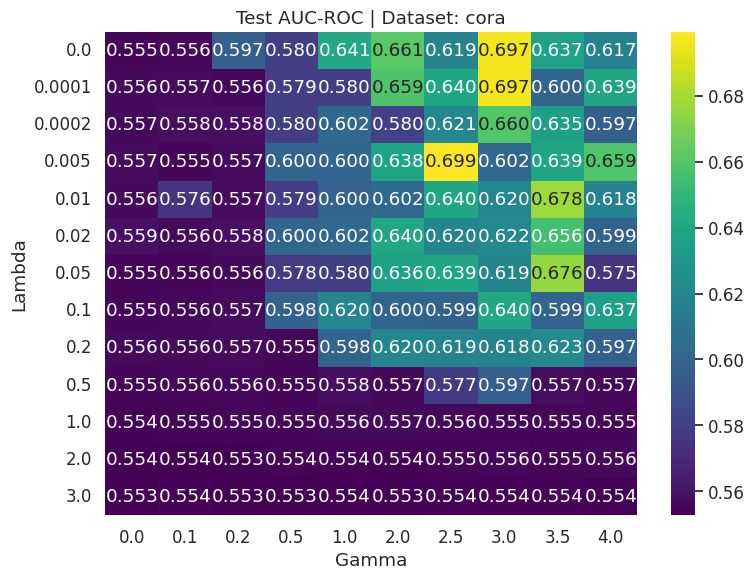


📊 Dataset: imdb


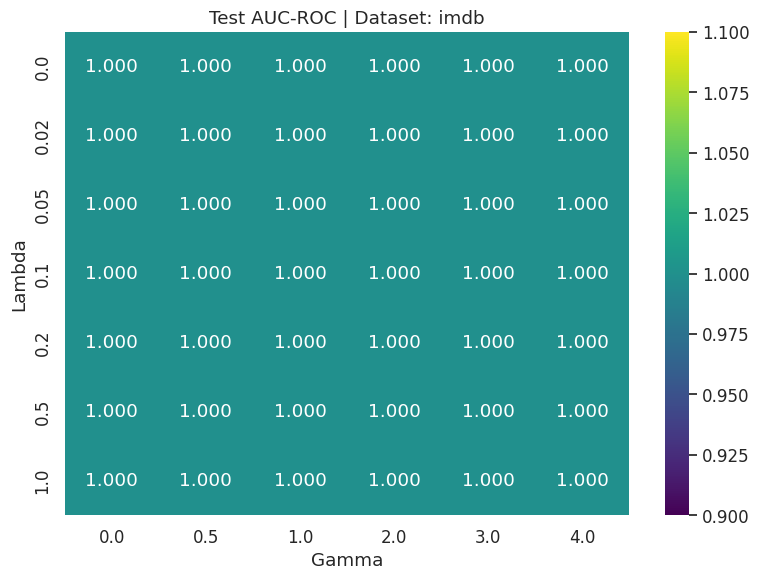


📊 Dataset: nell_finances


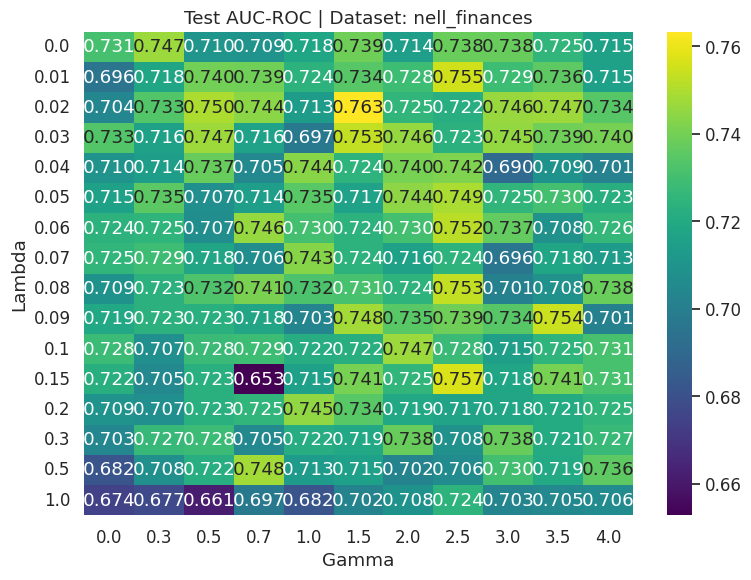


📊 Dataset: nell_sports


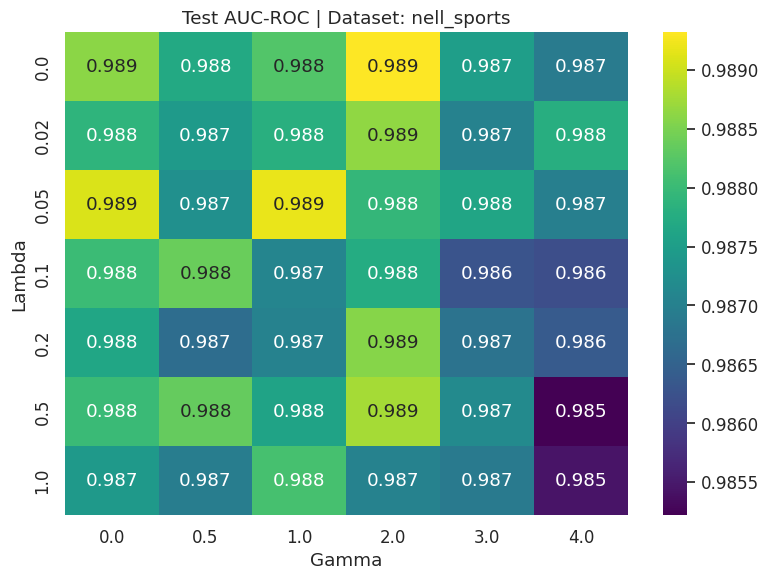


📊 Dataset: twitter


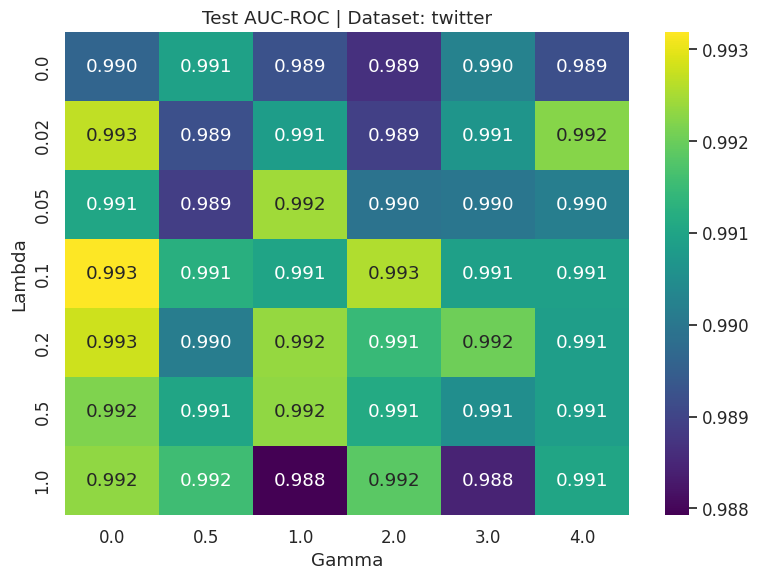


📊 Dataset: uwcse


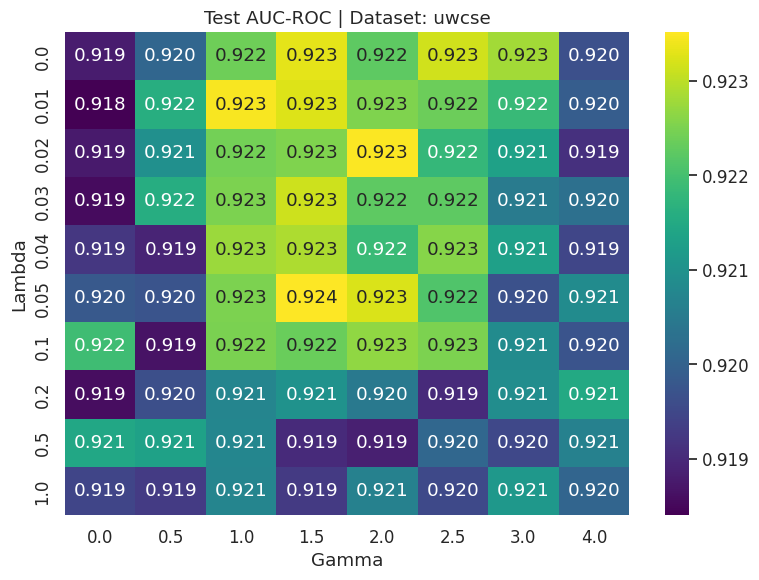


📊 Dataset: yeast


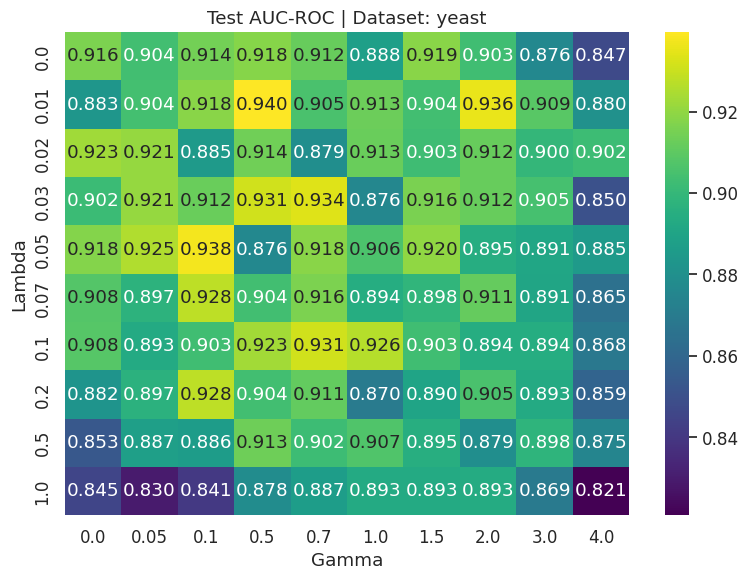

In [7]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_roc_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-ROC | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()



📊 Dataset: cora


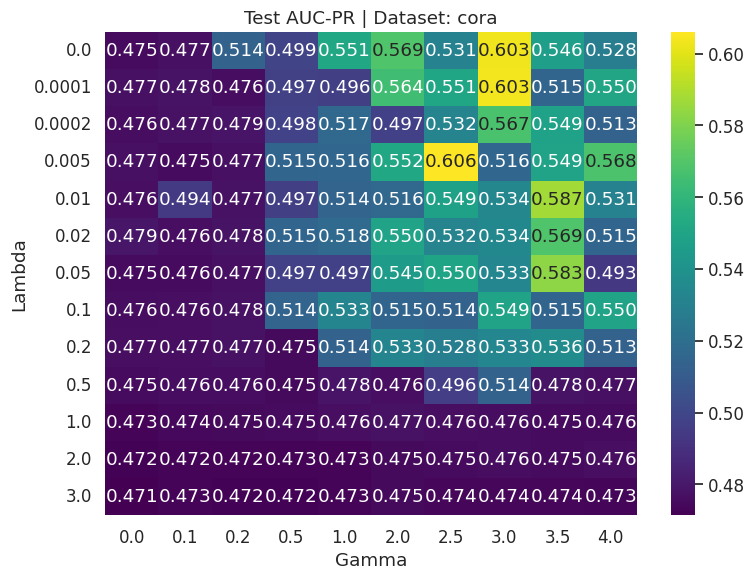


📊 Dataset: imdb


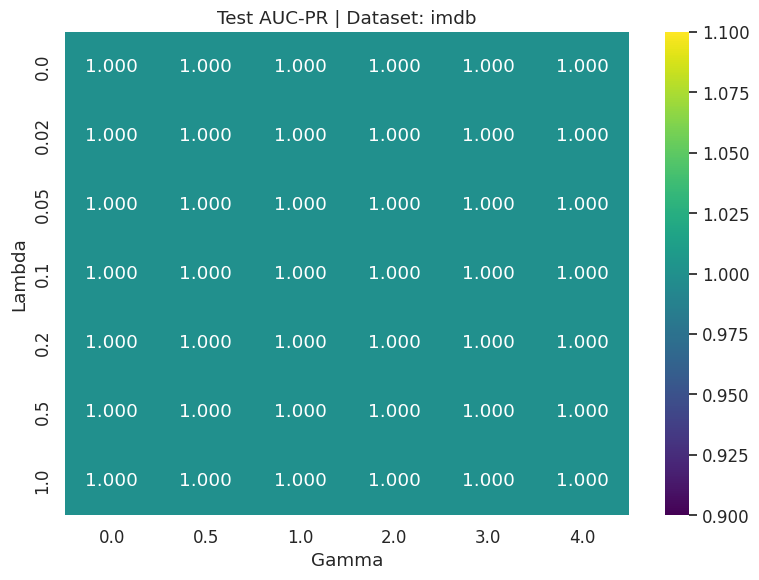


📊 Dataset: nell_finances


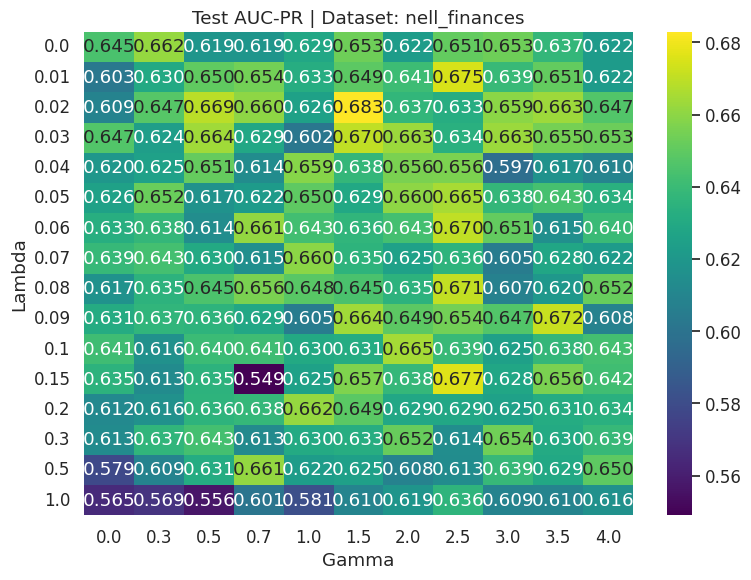


📊 Dataset: nell_sports


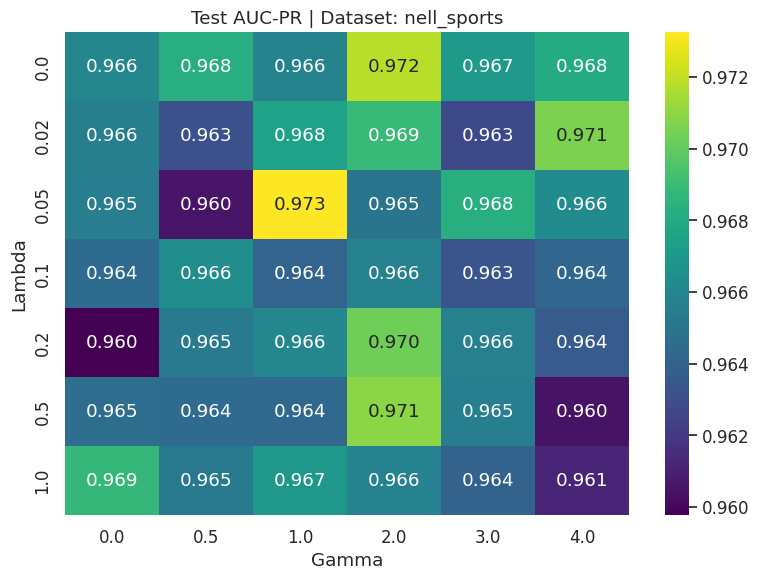


📊 Dataset: twitter


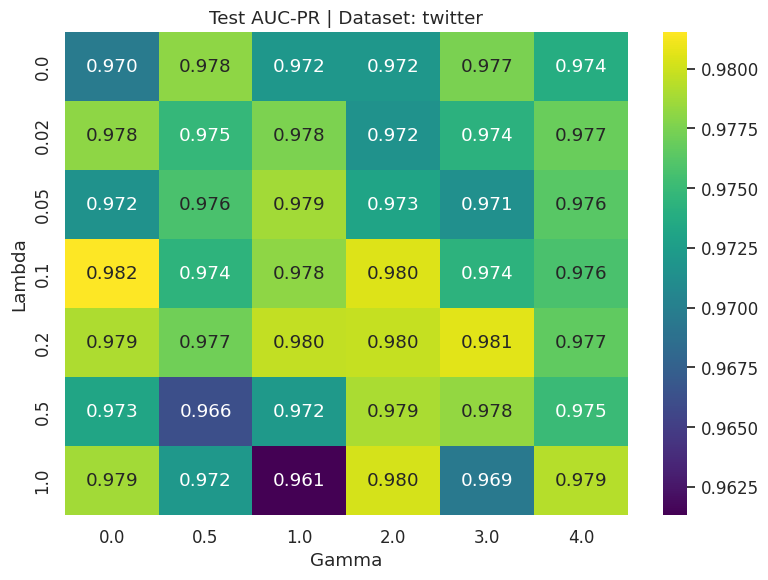


📊 Dataset: uwcse


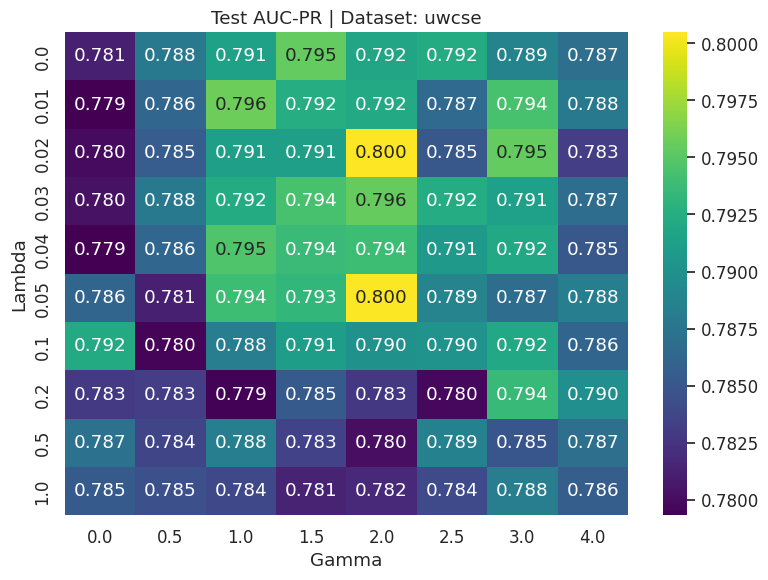


📊 Dataset: yeast


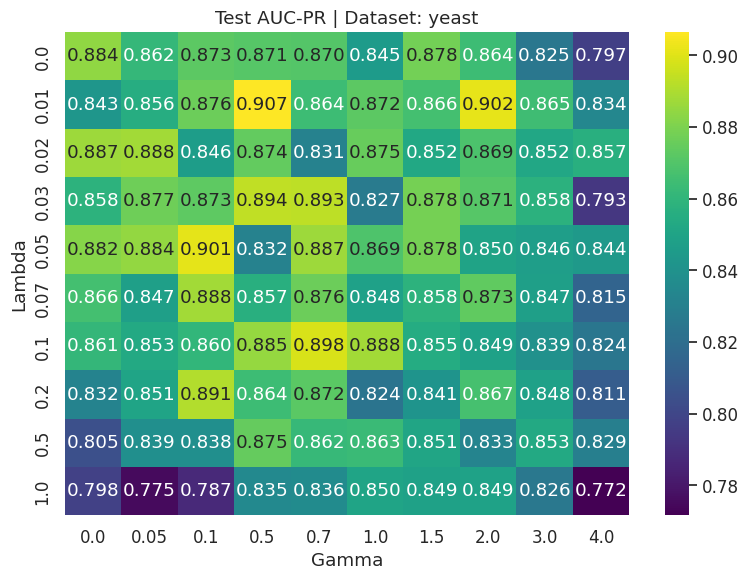

In [9]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_pr_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-PR | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


## Large Datasets - GFL RDN Boost

In [8]:
import json
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

datasets = ['imdb', 'cora', 'twitter', 'nell_finances', 'nell_sports', 'yeast', 'uwcse']
#datasets = ['nell_sports', 'cora', 'imdb', 'twitter', 'nell_finances']

records = []

for dataset in datasets:
    file_name = base_path / f"large_dataset_results_gfl_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        print(exp)
        gamma = exp.get("focal_loss_gamma")
        lambd = exp.get("boxcox_lambda")

        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "gamma": gamma,
                "lambda": lambd,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset", "gamma", "lambda"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

#display(summary.head())


{'focal_loss_gamma': 0, 'boxcox_lambda': 0, 'rdn_version': 'gflRdn', 'results': [{'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 447, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 295, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 420, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 315, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 453, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inferen


📊 Dataset: cora
cora


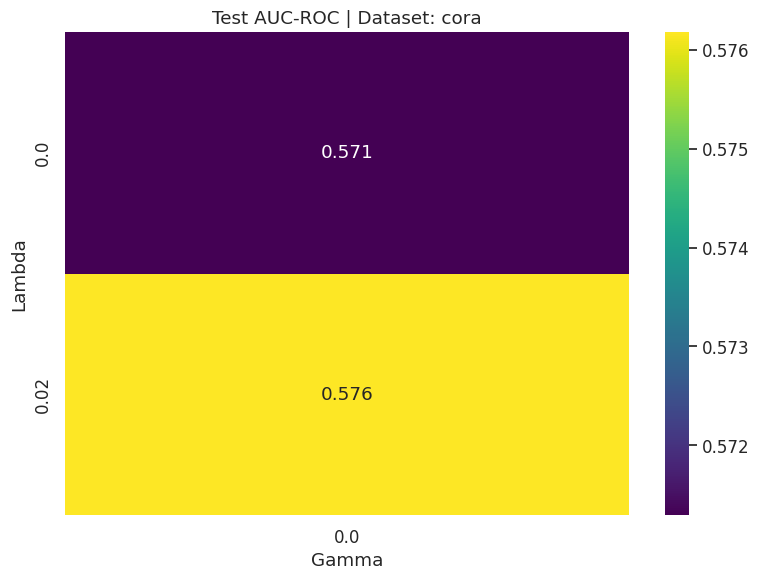


📊 Dataset: imdb
imdb


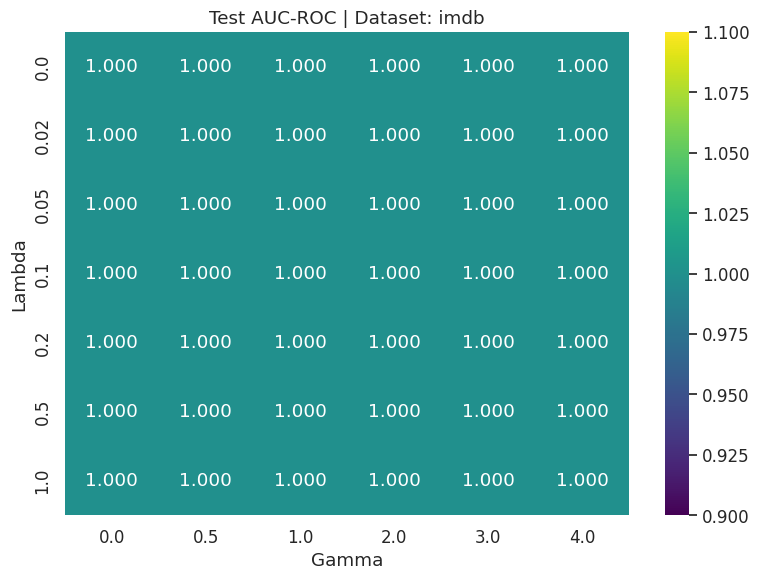


📊 Dataset: nell_finances
nell_finances


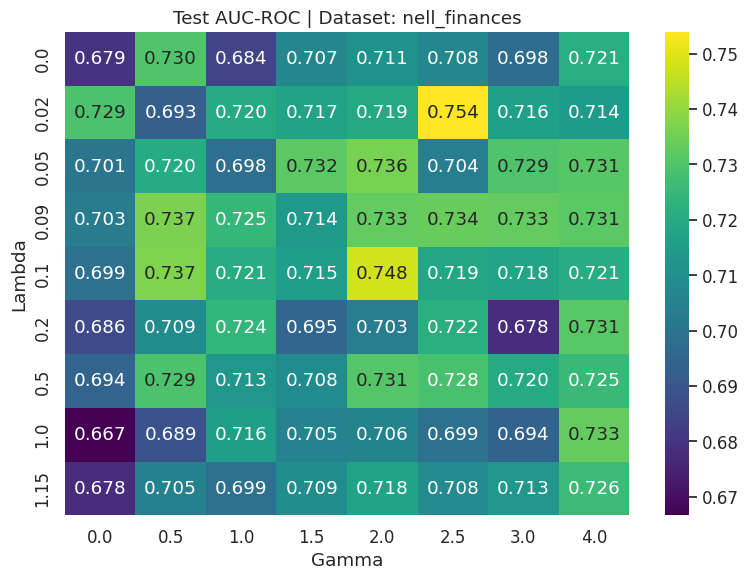


📊 Dataset: nell_sports
nell_sports


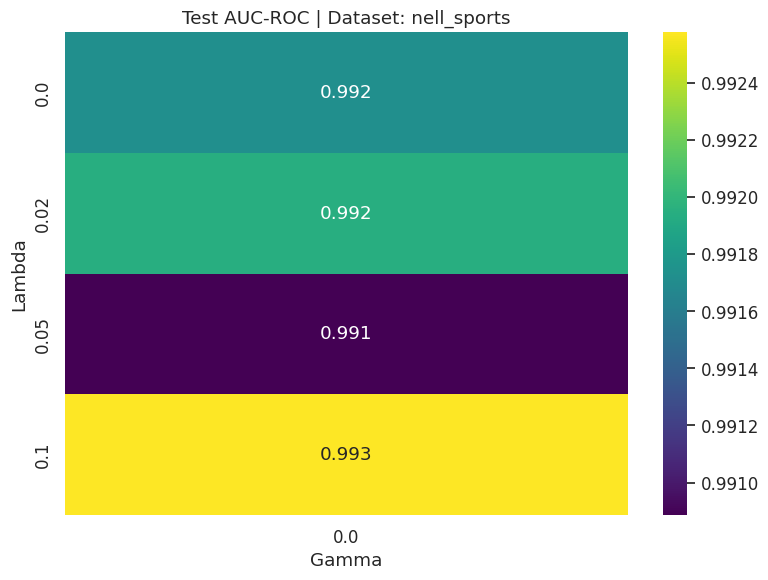


📊 Dataset: twitter
twitter


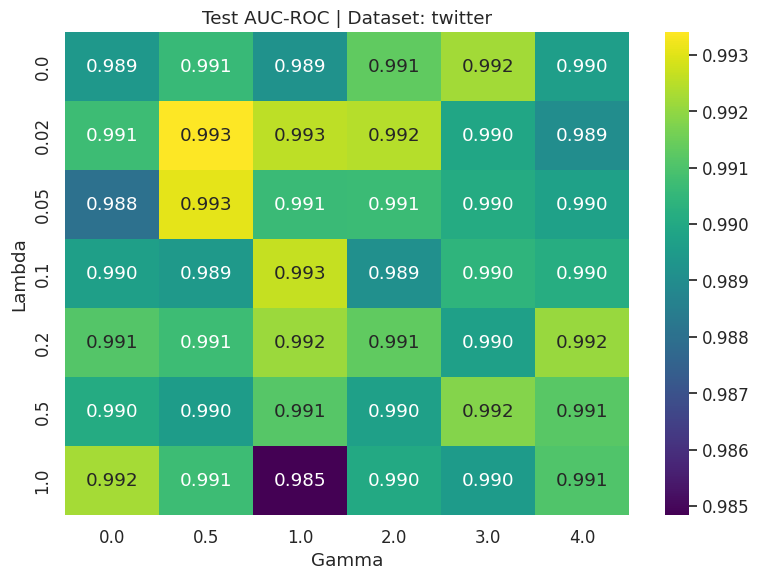


📊 Dataset: uwcse
uwcse


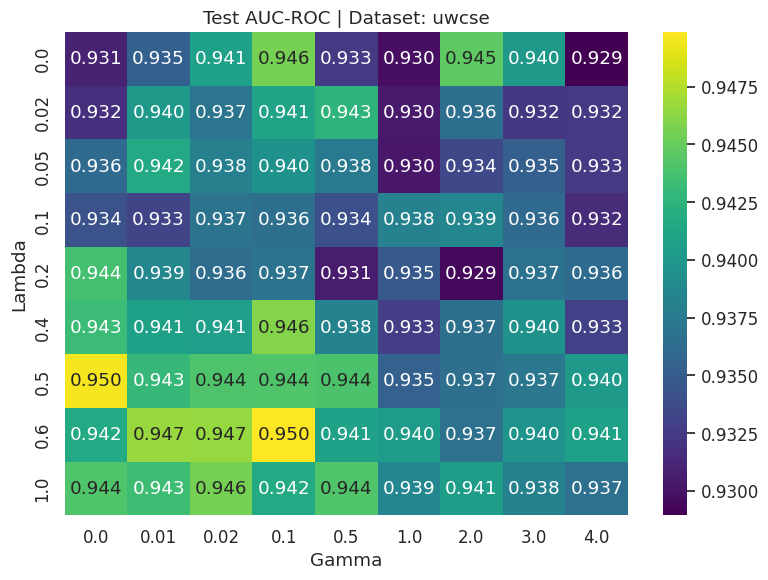


📊 Dataset: yeast
yeast


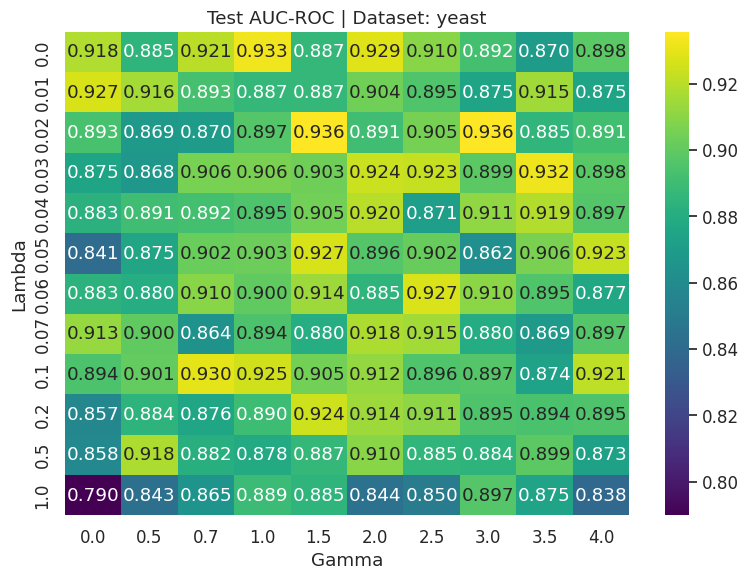

In [9]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    print(dataset)

    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_roc_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-ROC | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


In [18]:
data_ds

,dataset,gamma,lambda,train_auc_roc_mean,train_auc_roc_std,test_auc_roc_mean,test_auc_roc_std,train_auc_pr_mean,train_auc_pr_std,test_auc_pr_mean,test_auc_pr_std
0,cora,0.0,0.00,0.588358,0.050857,0.555244,0.010601,0.520528,0.128542,0.475202,0.035917
1,cora,0.0,0.01,0.588767,0.045541,0.556308,0.010687,0.521299,0.122529,0.476332,0.035366
2,cora,0.0,0.02,0.592783,0.049950,0.558598,0.012384,0.527141,0.123289,0.479049,0.037885
3,cora,0.0,0.05,0.586842,0.051568,0.555143,0.010535,0.517622,0.128062,0.475219,0.035697
4,cora,0.0,0.10,0.588029,0.049671,0.555370,0.011918,0.519665,0.130162,0.475877,0.036805
...,...,...,...,...,...,...,...,...,...,...,...
75,cora,4.0,0.20,0.638422,0.129658,0.597201,0.108729,0.583843,0.157153,0.513112,0.114700
76,cora,4.0,0.50,0.588678,0.049468,0.556566,0.009925,0.520285,0.127109,0.476672,0.034877
77,cora,4.0,1.00,0.584217,0.047297,0.555268,0.010432,0.513863,0.129508,0.475560,0.034604
78,cora,4.0,2.00,0.584599,0.046895,0.555705,0.010510,0.514453,0.128705,0.476245,0.035412


In [16]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_pr_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-PR | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


- Usar a mesma versão do RDN-Boost que o Cainã usou.
- Refazer os experimentos com o RDN-Boost original (versão do Cainã) e com o RDN-Boost Alpha Fairness.
- Tentar replicar os resultados com alguma configuração do Generalized Focal Loss.
- Explorar variações nas configurações que trazem melhores resultados.

In [5]:
import json
import pandas as pd
import numpy as np
import os
import math

arquivos = [
    "small_dataset_results_gfl_cora.json",
    "small_dataset_results_gfl_imdb.json",
    "small_dataset_results_gfl_nell_finances.json",
    "small_dataset_results_gfl_nell_sports.json",
    "small_dataset_results_gfl_twitter.json",
    "small_dataset_results_gfl_uwcse.json",
    "small_dataset_results_gfl_yeast.json"
]

for arquivo in arquivos:
    nome_dataset = arquivo.replace("small_dataset_results_gfl_", "").replace(".json", "")
    
    if not os.path.exists(arquivo):
        continue

    with open(arquivo, 'r') as f:
        data = json.load(f)

    records = []
    for run in data:
        alpha = run.get('boxcox_lambda', 0.0) 
        gamma = run.get('focal_loss_gamma', 0.0)
        
        if 'results' in run:
            auc_rocs = [fold['test']['auc_roc'] for fold in run['results'] if 'test' in fold]
            if auc_rocs:
                records.append({'alpha': alpha, 'gamma': gamma, 'auc_roc': np.mean(auc_rocs)})

    df = pd.DataFrame(records)
    if df.empty:
        continue

    heatmap_df = df.pivot(index='alpha', columns='gamma', values='auc_roc')
    
    max_val = float(heatmap_df.max().max())
    min_val = float(heatmap_df.min().min())

    alphas = sorted(df['alpha'].unique())
    gammas = sorted(df['gamma'].unique())

    latex_coords = ""
    for y_idx, alpha_val in enumerate(alphas):
        row_str = ""
        for x_idx, gamma_val in enumerate(gammas):
            val = heatmap_df.loc[alpha_val, gamma_val]
            if pd.isna(val):
                val = 0.0
            row_str += f"({x_idx},{y_idx}) [{val:.3f}] "
        latex_coords += row_str.strip() + "\n"

    num_cols = len(gammas)
    num_rows = len(alphas)
    
    x_tick_str = ",".join(str(i) for i in range(num_cols))
    x_ticklabel_str = ",".join(str(g) for g in gammas)
    
    y_tick_str = ",".join(str(i) for i in range(num_rows))
    y_ticklabel_str = ",".join(str(a) for a in alphas)

    # ==== CÁLCULO INTELIGENTE DOS TICKS DA BARRA DE CORES ====
    scale_range = max_val - min_val
    if scale_range <= 0.001:
        step = 0.0002
    elif scale_range <= 0.01:
        step = 0.002
    elif scale_range <= 0.05:
        step = 0.01
    elif scale_range <= 0.15:
        step = 0.02
    elif scale_range <= 0.3:
        step = 0.05
    else:
        step = 0.1
        
    # Evita divisão por zero se max_val == min_val (como ocorre no dataset IMDB)
    if scale_range == 0:
        cbar_ytick_str = f"{min_val:.3f}"
    else:
        first_tick = math.ceil(min_val / step) * step
        standard_ticks = []
        t = first_tick
        # Interrompe os ticks automáticos antes que eles "encostem" no valor máximo
        while t < max_val - (step * 0.4):
            standard_ticks.append(t)
            t += step
        cbar_ytick_str = ",".join([f"{tk:.3f}" for tk in standard_ticks])
    # =========================================================

    # Escapando o underline para não quebrar a formatação do título no LaTeX
    nome_dataset_title = nome_dataset.replace('_', '\\_')

    print(f"% ==========================================================")
    print(f"% DATASET: {nome_dataset.upper()} | MESH: {num_cols}x{num_rows} | MAX VAL: {max_val:.3f}")
    print(f"% ==========================================================")
    print(r"\begin{tikzpicture}")
    print(r"\begin{axis}[")
    print(f"    title={{\\texttt{{{nome_dataset_title}}}: GFL loss surface}},")
    print(r"    title style={font=\normalsize},")
    print(r"    xlabel={$\gamma$},")
    print(r"    ylabel={$\alpha$},")
    print(r"    label style={font=\normalsize},")
    print(r"    tick label style={font=\small},")
    print(f"    xtick={{{x_tick_str}}}, xticklabels={{{x_ticklabel_str}}}, x tick label style={{rotate=45,anchor=east}},")
    print(f"    ytick={{{y_tick_str}}}, yticklabels={{{y_ticklabel_str}}},")
    print(r"    y dir=reverse, enlargelimits=false, axis on top,")
    print(f"    point meta min={min_val:.3f},")
    print(f"    point meta max={max_val:.3f},")
    
    # === BARRA DE CORES COM MÁXIMA PRECISÃO E PROTEÇÃO ===
    print(f"    colorbar, colorbar style={{")
    print(r"        yticklabel style={/pgf/number format/fixed, /pgf/number format/precision=3, font=\small},")
    print(r"        title={AUC-ROC}, title style={font=\normalsize},")
    print(f"        ytick={{{cbar_ytick_str}}},")
    print(f"        extra y ticks={{{max_val:.3f}}},")
    print(r"        extra y tick style={yticklabel style={font=\small\bfseries, fill=white, inner sep=1pt}}")
    print(f"    }},")
    # =======================================================
    
    print(r"    colormap={gflmap}{rgb255(0cm)=(68,1,84); rgb255(1cm)=(33,145,140); rgb255(2cm)=(253,231,37)}")
    print(r"]")
    print(f"\\addplot[matrix plot*, mesh/cols={num_cols}, point meta=explicit] coordinates {{")
    print(latex_coords.strip())
    print(r"};")
    print(r"\end{axis}")
    print(r"\end{tikzpicture}")
    print("\n")

% ==========================================================
% DATASET: CORA | MESH: 10x13 | MAX VAL: 0.699
% ==========================================================
\begin{tikzpicture}
\begin{axis}[
    title={\texttt{cora}: GFL loss surface},
    title style={font=\normalsize},
    xlabel={$\gamma$},
    ylabel={$\alpha$},
    label style={font=\normalsize},
    tick label style={font=\small},
    xtick={0,1,2,3,4,5,6,7,8,9}, xticklabels={0.0,0.1,0.2,0.5,1.0,2.0,2.5,3.0,3.5,4.0}, x tick label style={rotate=45,anchor=east},
    ytick={0,1,2,3,4,5,6,7,8,9,10,11,12}, yticklabels={0.0,0.0001,0.0002,0.005,0.01,0.02,0.05,0.1,0.2,0.5,1.0,2.0,3.0},
    y dir=reverse, enlargelimits=false, axis on top,
    point meta min=0.553,
    point meta max=0.699,
    colorbar, colorbar style={
        yticklabel style={/pgf/number format/fixed, /pgf/number format/precision=3, font=\small},
        title={AUC-ROC}, title style={font=\normalsize},
        ytick={0.560,0.580,0.600,0.620,0.640,0.660,0.68